# TextureGuard AI — Artificial Texture Defect Classification

Nama : Evan Rafa Radya Alifian

NIM : 240411100063

Kelas : Machine Learning - E

---

**TextureGuard AI** adalah proyek pembelajaran mesin untuk mengklasifikasikan citra tekstur buatan dengan menggunakan ekstraksi fitur yang dirancang secara manual (*handcrafted feature extraction*) serta pembelajaran mesin otomatis (*Automated Machine Learning* atau AutoML).

Proyek ini menggunakan **kumpulan data DAGM 2007**, **PyFeats** untuk ekstraksi fitur tekstur dengan metode **Local Binary Pattern (LBP)**, serta **PyCaret** untuk membandingkan dan mengevaluasi model klasifikasi pembelajaran mesin.

## Sumber Dataset

- **Nama dataset**: DAGM 2007 — *Weakly Supervised Learning for Industrial Optical Inspection*
- **Penyedia**: DAGM (German Association for Pattern Recognition) bersama HCI, Universitas Heidelberg
- **Tautan unduhan**: https://conferences.mpi-inf.mpg.de/dagm/2007/prizes.html
- **Berkas yang digunakan**: `Class1.zip` s.d. `Class6.zip`, diekstrak ke `datasets/raw/Class1` ... `datasets/raw/Class6`
- **Karakteristik**: citra tekstur buatan (*artificial texture*) grayscale 8-bit berukuran 512 × 512 piksel. Tiap kelas memiliki latar tekstur dengan karakter berbeda.
- **Jumlah data**: 6 kelas × 1000 citra = 6000 citra (seimbang)

**Rumusan tugas klasifikasi**: *multikelas* (6 kelas). Label diambil dari nama folder (`Class1` ... `Class6`).

# TextureGuard AI — Image Preprocessing

Tahap ini bertujuan untuk memeriksa struktur dataset DAGM 2007,
memvalidasi citra, dan menyiapkan gambar untuk ekstraksi fitur tekstur.

## Periksa struktur folder dan jumlah gambar

In [1]:
from pathlib import Path
from collections import Counter

DATASET_DIR = Path("../datasets/raw")

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Folder tidak ditemukan: {DATASET_DIR.resolve()}")

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

print("Lokasi dataset:", DATASET_DIR.resolve())
print("\nStruktur folder kelas:\n")

for folder in sorted(DATASET_DIR.iterdir()):
    if folder.is_dir():
        files = [p for p in folder.rglob("*") if p.is_file()]

        images = [p for p in files if p.suffix.lower() in IMAGE_EXTENSIONS]

        print(
            f"{folder.name}: "
            f"{len(images)} gambar, "
            f"{len(files) - len(images)} file lain"
        )

Lokasi dataset: C:\Users\acer\Desktop\evanalifian\textureguard-ai-dagm2007\datasets\raw

Struktur folder kelas:

Class1: 1000 gambar, 0 file lain
Class2: 1000 gambar, 0 file lain
Class3: 1000 gambar, 0 file lain
Class4: 1000 gambar, 0 file lain
Class5: 1000 gambar, 0 file lain
Class6: 1000 gambar, 0 file lain


In [2]:
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_files = [
  path
  for path in DATASET_DIR.rglob("*")
  if path.is_file() and path.suffix.lower() in image_extensions
]

extension_counts = Counter(path.suffix.lower() for path in image_files)

print("Total file gambar:", len(image_files))
print("\nJumlah gambar berdasarkan ekstensi:")

for extension, count in sorted(extension_counts.items()):
  print(f"{extension}: {count}")

print("\nContoh file gambar:")
for path in image_files[:10]:
  print(path.relative_to(DATASET_DIR))

Total file gambar: 6000

Jumlah gambar berdasarkan ekstensi:
.png: 6000

Contoh file gambar:
Class1\1.png
Class1\10.png
Class1\100.png
Class1\1000.png
Class1\101.png
Class1\102.png
Class1\103.png
Class1\104.png
Class1\105.png
Class1\106.png


## Tampilkan contoh gambar dari setiap kelas

In [3]:
import cv2
import matplotlib.pyplot as plt
import math

class_folders = sorted(p for p in DATASET_DIR.iterdir() if p.is_dir())

samples = []

for folder in class_folders:
    images = sorted(
        p
        for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    if images:
        samples.append((folder.name, images[0]))

if not samples:
    raise ValueError("Tidak ditemukan gambar dalam folder kelas.")

columns = 3
rows = math.ceil(len(samples) / columns)

fig, axes = plt.subplots(rows, columns, figsize=(12, 4 * rows), squeeze=False)

for ax in axes.flat:
    ax.axis("off")

for ax, (class_name, image_path) in zip(axes.flat, samples):
    image = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)

    if image is None:
        ax.set_title(f"{class_name}: gagal dibaca")
        continue

    if image.ndim == 2:
        ax.imshow(image, cmap="gray")
    elif image.ndim == 3 and image.shape[2] == 3:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    elif image.ndim == 3 and image.shape[2] == 4:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGRA2RGBA))
    else:
        ax.text(0.5, 0.5, f"Shape: {image.shape}", ha="center")

    ax.set_title(f"{class_name}\n{image_path.name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

<Figure size 1200x800 with 6 Axes>

## Periksa dimensi, kanal warna, dan tipe data

In [4]:
import pandas as pd

records = []

for folder in class_folders:
    for image_path in folder.rglob("*"):
        if (
            not image_path.is_file()
            or image_path.suffix.lower() not in IMAGE_EXTENSIONS
        ):
            continue

        image = cv2.imread(str(image_path), cv2.IMREAD_UNCHANGED)

        record = {
            "class": folder.name,
            "filename": image_path.name,
            "path": str(image_path),
            "readable": image is not None,
        }

        if image is not None:
            record["height"] = image.shape[0]
            record["width"] = image.shape[1]
            record["channels"] = 1 if image.ndim == 2 else image.shape[2]
            record["dtype"] = str(image.dtype)
            record["min_pixel"] = int(image.min())
            record["max_pixel"] = int(image.max())

        records.append(record)

image_info = pd.DataFrame(records)

print("Jumlah gambar:", len(image_info))
print("\nGambar gagal dibaca:")
print((~image_info["readable"]).sum())

print("\nDistribusi jumlah gambar per kelas:")
print(image_info.groupby("class").size())

print("\nDistribusi dimensi:")
print(
    image_info.groupby(["width", "height", "channels", "dtype"])
    .size()
    .sort_values(ascending=False)
    .head(20)
)

display(image_info.head())

Jumlah gambar: 6000

Gambar gagal dibaca:
0

Distribusi jumlah gambar per kelas:
class
Class1    1000
Class2    1000
Class3    1000
Class4    1000
Class5    1000
Class6    1000
dtype: int64

Distribusi dimensi:
width  height  channels  dtype
512    512     1         uint8    6000
dtype: int64


,class,filename,path,readable,height,width,channels,dtype,min_pixel,max_pixel
0,Class1,1.png,..\datasets\raw\Class1\1.png,True,512,512,1,uint8,0,255
1,Class1,10.png,..\datasets\raw\Class1\10.png,True,512,512,1,uint8,0,255
2,Class1,100.png,..\datasets\raw\Class1\100.png,True,512,512,1,uint8,0,252
3,Class1,1000.png,..\datasets\raw\Class1\1000.png,True,512,512,1,uint8,0,252
4,Class1,101.png,..\datasets\raw\Class1\101.png,True,512,512,1,uint8,0,253


In [5]:
# Hitung semua jenis file di seluruh subfolder
file_counts = Counter(
    path.suffix.lower() or "[tanpa ekstensi]"
    for path in DATASET_DIR.rglob("*")
    if path.is_file()
)

print("Jenis file dalam dataset:")
for extension, count in sorted(file_counts.items()):
    print(f"{extension}: {count}")

print("\nStruktur folder hingga 4 tingkat:")
for path in sorted(DATASET_DIR.rglob("*")):
    relative_path = path.relative_to(DATASET_DIR)

    if len(relative_path.parts) <= 4 and path.is_dir():
        print(f"[DIR] {relative_path}")

print("\nContoh nama file dari setiap kelas:")
for folder in sorted(p for p in DATASET_DIR.iterdir() if p.is_dir()):
    files = sorted(p for p in folder.rglob("*") if p.is_file())

    print(f"\n{folder.name}:")
    for path in files[:8]:
        print(" ", path.relative_to(DATASET_DIR))

Jenis file dalam dataset:
.png: 6000

Struktur folder hingga 4 tingkat:
[DIR] Class1
[DIR] Class2
[DIR] Class3
[DIR] Class4
[DIR] Class5
[DIR] Class6

Contoh nama file dari setiap kelas:

Class1:
  Class1\1.png
  Class1\10.png
  Class1\100.png
  Class1\1000.png
  Class1\101.png
  Class1\102.png
  Class1\103.png
  Class1\104.png

Class2:
  Class2\1.png
  Class2\10.png
  Class2\100.png
  Class2\1000.png
  Class2\101.png
  Class2\102.png
  Class2\103.png
  Class2\104.png

Class3:
  Class3\1.png
  Class3\10.png
  Class3\100.png
  Class3\1000.png
  Class3\101.png
  Class3\102.png
  Class3\103.png
  Class3\104.png

Class4:
  Class4\1.png
  Class4\10.png
  Class4\100.png
  Class4\1000.png
  Class4\101.png
  Class4\102.png
  Class4\103.png
  Class4\104.png

Class5:
  Class5\1.png
  Class5\10.png
  Class5\100.png
  Class5\1000.png
  Class5\101.png
  Class5\102.png
  Class5\103.png
  Class5\104.png

Class6:
  Class6\1.png
  Class6\10.png
  Class6\100.png
  Class6\1000.png
  Class6\101.png
  Clas

In [6]:
class_folders = sorted(
    p for p in DATASET_DIR.iterdir()
    if p.is_dir()
)

print("Folder yang terdeteksi sebagai kelas:")
for folder in class_folders:
    print("-", folder.name)

Folder yang terdeteksi sebagai kelas:
- Class1
- Class2
- Class3
- Class4
- Class5
- Class6


## Konfigurasi dan pemeriksaan environment

Library yang dibutuhkan: `pyfeats`, `pycaret`, `opencv-python`, `pandas`, `scikit-learn`, `matplotlib`, `seaborn`, `joblib`.
PyCaret 3.x mendukung **Python 3.9 – 3.11**. Daftar lengkap ada di `requirements.txt`.

In [7]:
# !pip install pyfeats "pycaret[analysis]" opencv-python seaborn joblib   # jalankan sekali jika belum terpasang

import sys, time, warnings
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
IMG_SIZE = 128           # ukuran sisi citra setelah resize (piksel)
TEST_SIZE = 0.20         # proporsi data uji (hold-out akhir, tidak disentuh PyCaret)
FORCE_REEXTRACT = False  # True = hitung ulang fitur walau CSV sudah ada

PROCESSED_DIR = Path("../datasets/processed")
RESULTS_DIR = Path("../results")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_CSV = PROCESSED_DIR / "features_lbp_dagm2007.csv"
TRAIN_CSV = PROCESSED_DIR / "train_lbp_features.csv"
TEST_CSV = PROCESSED_DIR / "test_lbp_features.csv"

print("Python :", sys.version.split()[0])
for pkg in ["numpy", "pandas", "scikit-learn", "opencv-python", "pyfeats", "pycaret"]:
    try:
        print(f"{pkg:14s}:", version(pkg))
    except PackageNotFoundError:
        print(f"{pkg:14s}: (tidak terpasang / nama paket berbeda)")

Python : 3.11.0
numpy         : 1.26.4
pandas        : 2.1.4
scikit-learn  : 1.4.2
opencv-python : 4.11.0.86
pyfeats       : 1.0.1
pycaret       : 3.3.2


## Fungsi pra-pemrosesan citra

Langkah yang diterapkan pada setiap citra:

1. **Konversi ke grayscale** — data sudah 1 kanal, tetapi dipaksa lewat `IMREAD_GRAYSCALE` agar konsisten.
2. **Resize** ke `IMG_SIZE × IMG_SIZE` dengan interpolasi `INTER_AREA` (cocok untuk pengecilan, menjaga detail tekstur). Ini juga mempercepat ekstraksi fitur secara signifikan.
3. **Tipe data `uint8` (0–255) dipertahankan** — LBP membandingkan intensitas piksel pusat dengan piksel-piksel tetangganya pada nilai keabuan asli, dan PyFeats mengharapkan citra bertipe bilangan bulat, sehingga citra tidak dinormalisasi ke rentang 0–1.

**Augmentasi tidak digunakan** karena data sudah besar (1000 citra/kelas) dan seimbang. Rotasi/flip pada citra tekstur juga mengubah pola biner lokal yang menjadi dasar perhitungan LBP.
**Normalisasi** dilakukan pada level *fitur* di dalam `setup()` PyCaret (`normalize=True`), bukan pada piksel, agar tidak terjadi kebocoran informasi dari data uji.

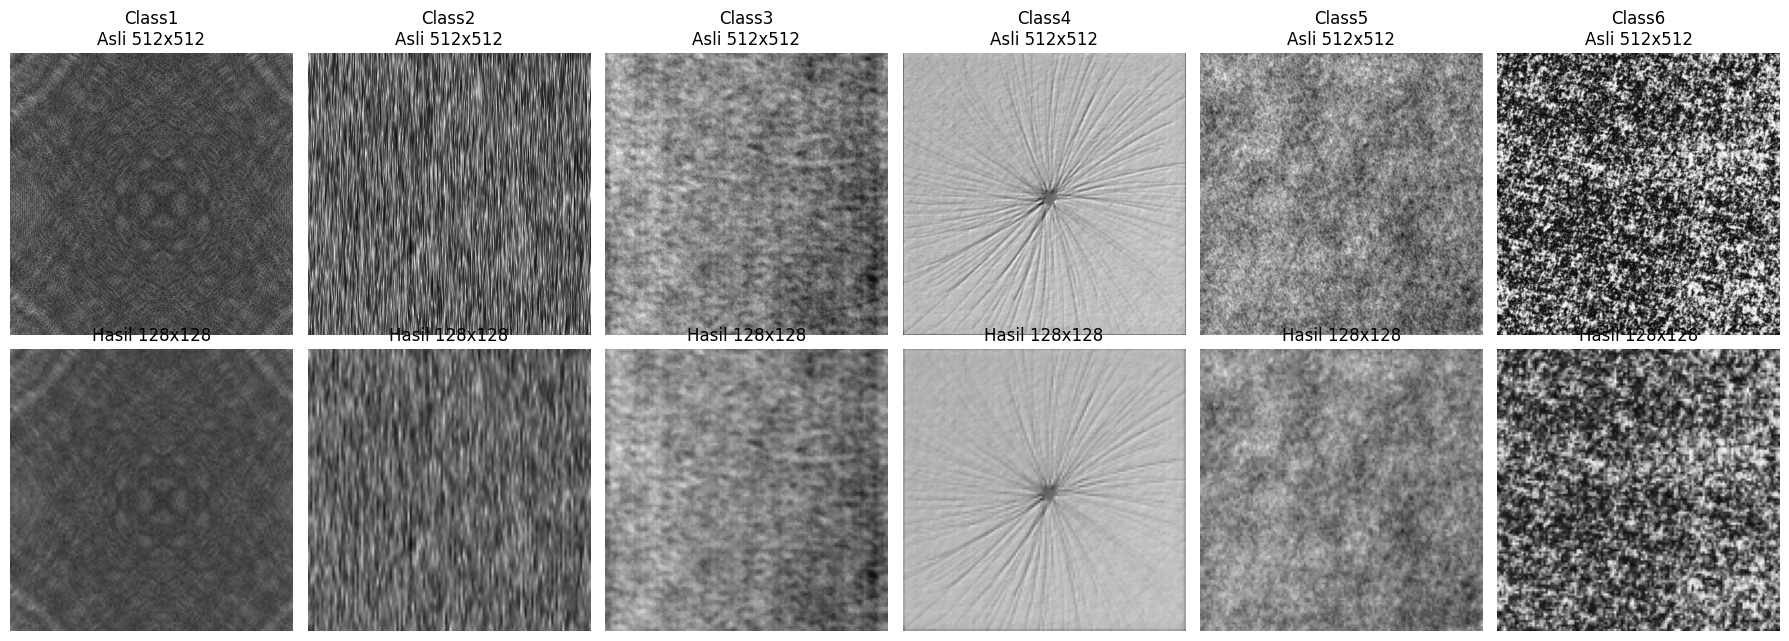

In [8]:
def preprocess_image(image_path, size=IMG_SIZE):
    '''Baca citra -> grayscale -> resize -> uint8 (0-255).'''
    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Gagal membaca citra: {image_path}")
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    return img.astype(np.uint8)


# Perbandingan sebelum vs sesudah pra-pemrosesan (satu contoh per kelas)
fig, axes = plt.subplots(2, len(samples), figsize=(3 * len(samples), 6.4), squeeze=False)

for col, (class_name, image_path) in enumerate(samples):
    raw = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    proc = preprocess_image(image_path)

    axes[0, col].imshow(raw, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{class_name}\nAsli {raw.shape[1]}x{raw.shape[0]}")
    axes[1, col].imshow(proc, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"Hasil {proc.shape[1]}x{proc.shape[0]}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_preprocessing_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

# TextureGuard AI — Feature Extraction (PyFeats: Local Binary Pattern)

Ekstraksi fitur pada proyek ini menggunakan **satu metode, yaitu Local Binary Pattern (LBP)** melalui fungsi `pyfeats.lbp_features`.

**Cara kerja LBP.** Untuk setiap piksel, intensitas piksel pusat dibandingkan dengan `P` piksel tetangga yang tersebar pada lingkaran berjari-jari `R`. Tetangga yang intensitasnya ≥ pusat diberi bit 1, selainnya bit 0, sehingga terbentuk kode biner lokal. Dengan pemetaan *uniform*, kode dikelompokkan menjadi `P + 2` pola (tepi, sudut, area datar, dan sebagainya), lalu hasilnya menjadi citra LBP.

**Ringkasan fitur oleh PyFeats.** Untuk setiap pasangan `(P, R)`, citra LBP diringkas menjadi 2 angka:
- `energy`: keseragaman distribusi kode LBP
- `entropy`: ukuran keacakan/kerumitan distribusi kode LBP

*Catatan*: PyFeats menghitung kedua nilai ini langsung dari nilai kode pada citra LBP (bukan dari histogram yang dinormalisasi), sehingga `entropy` dapat bernilai negatif dan bukan entropi Shannon klasik. Nilainya tetap konsisten antar-citra dan bermanfaat sebagai fitur pembeda.

**Multi-resolusi.** Tekstur memiliki pola pada skala yang berbeda, sehingga dipakai 6 pasangan `(P, R)`:

| Skala | P (titik tetangga) | R (jari-jari) | Fitur |
|---|---|---|---|
| 1 | 8 | 1 | `LBP_R_1_P_8_energy`, `..._entropy` |
| 2 | 16 | 2 | `LBP_R_2_P_16_energy`, `..._entropy` |
| 3 | 24 | 3 | `LBP_R_3_P_24_energy`, `..._entropy` |
| 4 | 8 | 2 | `LBP_R_2_P_8_energy`, `..._entropy` |
| 5 | 16 | 4 | `LBP_R_4_P_16_energy`, `..._entropy` |
| 6 | 24 | 5 | `LBP_R_5_P_24_energy`, `..._entropy` |

Total **12 fitur** per citra. Proses dijalankan paralel (`joblib`) dan hasilnya disimpan ke CSV agar tidak perlu dihitung ulang.

*Referensi*: Ojala, Pietikäinen & Mäenpää (2002), "Multiresolution Gray-Scale and Rotation Invariant Texture Classification with Local Binary Patterns", IEEE TPAMI.

In [9]:
import pyfeats
from joblib import Parallel, delayed

# Skala LBP: (jumlah titik tetangga P, jari-jari R)
LBP_SCALES = [(8, 1), (16, 2), (24, 3), (8, 2), (16, 4), (24, 5)]
LBP_P = [p for p, r in LBP_SCALES]
LBP_R = [r for p, r in LBP_SCALES]


def extract_features(image_path):
    """Ekstraksi fitur Local Binary Pattern (PyFeats) dari satu citra.
    Mengembalikan dict {nama_fitur: nilai}."""
    import warnings
    warnings.filterwarnings("ignore")

    img = preprocess_image(image_path)
    mask = np.ones(img.shape, dtype=np.uint8)   # seluruh citra = ROI

    values, names = pyfeats.lbp_features(img, mask, P=LBP_P, R=LBP_R)
    return {n: float(v) for n, v in zip(names, values)}


# Uji cepat pada satu citra
t0 = time.time()
demo = extract_features(samples[0][1])
print(f"{len(demo)} fitur LBP dari 1 citra dalam {time.time() - t0:.3f} detik")
for k, v in demo.items():
    print(f"  {k:28s} {v:.6f}")

12 fitur LBP dari 1 citra dalam 0.028 detik
  LBP_R_1_P_8_energy           7.295767
  LBP_R_1_P_8_entropy          -1.919489
  LBP_R_2_P_16_energy          15.703029
  LBP_R_2_P_16_entropy         -2.717194
  LBP_R_3_P_24_energy          24.044827
  LBP_R_3_P_24_entropy         -3.158517
  LBP_R_2_P_8_energy           7.611043
  LBP_R_2_P_8_entropy          -1.967918
  LBP_R_4_P_16_energy          16.215529
  LBP_R_4_P_16_entropy         -2.761465
  LBP_R_5_P_24_energy          24.317832
  LBP_R_5_P_24_entropy         -3.175226


In [10]:
if FEATURES_CSV.exists() and not FORCE_REEXTRACT:
    features_raw = pd.read_csv(FEATURES_CSV)
    print(f"Memuat fitur dari cache: {FEATURES_CSV}  -> {features_raw.shape}")
else:
    paths = image_info.loc[image_info["readable"], "path"].tolist()
    labels = image_info.loc[image_info["readable"], "class"].tolist()
    names = image_info.loc[image_info["readable"], "filename"].tolist()

    t0 = time.time()
    rows = Parallel(n_jobs=-1, verbose=5)(delayed(extract_features)(p) for p in paths)
    print(f"Ekstraksi selesai: {len(rows)} citra dalam {(time.time() - t0) / 60:.1f} menit")

    features_raw = pd.DataFrame(rows)
    features_raw.insert(0, "label", labels)
    features_raw.insert(1, "filename", names)
    features_raw.to_csv(FEATURES_CSV, index=False)
    print(f"Disimpan ke {FEATURES_CSV}  -> {features_raw.shape}")

display(features_raw.head())

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=-1)]: Done  32 tasks      | elapsed:    3.3s
[Parallel(n_jobs=-1)]: Done 124 tasks      | elapsed:    3.5s
[Parallel(n_jobs=-1)]: Done 552 tasks      | elapsed:    4.5s
[Parallel(n_jobs=-1)]: Done 1200 tasks      | elapsed:    6.0s
[Parallel(n_jobs=-1)]: Done 1992 tasks      | elapsed:    8.0s
[Parallel(n_jobs=-1)]: Done 2928 tasks      | elapsed:   10.4s
[Parallel(n_jobs=-1)]: Done 4008 tasks      | elapsed:   13.1s
[Parallel(n_jobs=-1)]: Done 5232 tasks      | elapsed:   16.0s


Ekstraksi selesai: 6000 citra dalam 0.3 menit
Disimpan ke ..\datasets\processed\features_lbp_dagm2007.csv  -> (6000, 14)


[Parallel(n_jobs=-1)]: Done 5961 out of 6000 | elapsed:   17.7s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done 6000 out of 6000 | elapsed:   17.8s finished


,label,filename,LBP_R_1_P_8_energy,LBP_R_1_P_8_entropy,LBP_R_2_P_16_energy,LBP_R_2_P_16_entropy,LBP_R_3_P_24_energy,LBP_R_3_P_24_entropy,LBP_R_2_P_8_energy,LBP_R_2_P_8_entropy,LBP_R_4_P_16_energy,LBP_R_4_P_16_entropy,LBP_R_5_P_24_energy,LBP_R_5_P_24_entropy
0,Class1,1.png,7.295767,-1.919489,15.703029,-2.717194,24.044827,-3.158517,7.611043,-1.967918,16.215529,-2.761465,24.317832,-3.175226
1,Class1,10.png,7.614013,-1.974698,16.234772,-2.766503,24.448845,-3.184361,8.031706,-2.042928,16.428217,-2.783005,24.453799,-3.185659
2,Class1,100.png,7.649989,-1.980508,16.279864,-2.770990,24.508187,-3.187911,8.069759,-2.050509,16.390369,-2.779965,24.438301,-3.184962
3,Class1,1000.png,7.788480,-2.004423,16.271868,-2.769457,24.488495,-3.186664,7.944070,-2.027824,16.377288,-2.777588,24.408874,-3.182275
4,Class1,101.png,7.578719,-1.966668,16.125883,-2.755621,24.437321,-3.183355,7.920013,-2.023061,16.387031,-2.778312,24.424858,-3.182586


# TextureGuard AI — Pembersihan Data dan Partisi

Pemeriksaan kualitas tabel fitur: dimensi, tipe data, *missing values*, nilai tak hingga, fitur konstan, duplikat, dan *outlier*.

In [11]:
feature_cols = [c for c in features_raw.columns if c not in ("label", "filename")]

print("Dimensi tabel fitur :", features_raw.shape)
print("Jumlah fitur        :", len(feature_cols))
print("\nDistribusi kelas:")
print(features_raw["label"].value_counts().sort_index())

print("\nTipe data fitur:")
print(features_raw[feature_cols].dtypes.value_counts())

n_missing = features_raw[feature_cols].isna().sum()
n_inf = np.isinf(features_raw[feature_cols]).sum()

print("\nFitur dengan missing value :", int((n_missing > 0).sum()))
print("Fitur dengan nilai +/-inf  :", int((n_inf > 0).sum()))
print("Baris duplikat (fitur)     :", int(features_raw[feature_cols].duplicated().sum()))

problem = pd.DataFrame({"missing": n_missing, "inf": n_inf})
problem = problem[(problem > 0).any(axis=1)]
if len(problem):
    display(problem)
else:
    print("\nTidak ada missing value maupun nilai tak hingga.")

Dimensi tabel fitur : (6000, 14)
Jumlah fitur        : 12

Distribusi kelas:
label
Class1    1000
Class2    1000
Class3    1000
Class4    1000
Class5    1000
Class6    1000
Name: count, dtype: int64

Tipe data fitur:
float64    12
Name: count, dtype: int64

Fitur dengan missing value : 0
Fitur dengan nilai +/-inf  : 0
Baris duplikat (fitur)     : 0

Tidak ada missing value maupun nilai tak hingga.


In [12]:
features_clean = features_raw.copy()

# 1) +/-inf -> NaN (agar ditangani seragam sebagai missing value)
features_clean[feature_cols] = features_clean[feature_cols].replace([np.inf, -np.inf], np.nan)

# 2) Buang fitur yang seluruhnya kosong atau konstan (tidak informatif)
all_nan = [c for c in feature_cols if features_clean[c].isna().all()]
constant = [c for c in feature_cols if features_clean[c].nunique(dropna=True) <= 1 and c not in all_nan]
drop_cols = all_nan + constant
features_clean = features_clean.drop(columns=drop_cols)
feature_cols = [c for c in features_clean.columns if c not in ("label", "filename")]

print("Fitur dibuang (kosong/konstan):", drop_cols if drop_cols else "-")
print("Jumlah fitur sekarang         :", len(feature_cols))

# 3) Baris dengan terlalu banyak NaN (>50% fitur) dibuang
too_empty = features_clean[feature_cols].isna().mean(axis=1) > 0.5
print("Baris dibuang (>50% NaN)      :", int(too_empty.sum()))
features_clean = features_clean.loc[~too_empty].reset_index(drop=True)

# Sisa NaN (jika ada) TIDAK diimputasi di sini; diimputasi (median) di dalam pipeline PyCaret
# agar statistik imputasi hanya dipelajari dari data latih (tanpa kebocoran data).
print("Sisa NaN pada fitur           :", int(features_clean[feature_cols].isna().sum().sum()))
print("Dimensi akhir                 :", features_clean.shape)

Fitur dibuang (kosong/konstan): -
Jumlah fitur sekarang         : 12
Baris dibuang (>50% NaN)      : 0
Sisa NaN pada fitur           : 0
Dimensi akhir                 : (6000, 14)


### Pemeriksaan outlier (metode IQR)

Nilai dianggap *outlier* bila berada di luar `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]`. Pada fitur tekstur, nilai ekstrem sering merupakan variasi tekstur yang sah (bukan kesalahan data), sehingga baris **tidak dihapus**. Pengaruhnya dikurangi dengan *robust scaling* pada tahap PyCaret.

Total sel outlier: 7882 dari 72000 (10.95%)
Baris dengan >=1 outlier: 2137 dari 6000


,n_outlier,persen
LBP_R_1_P_8_energy,2128,35.47
LBP_R_1_P_8_entropy,2092,34.87
LBP_R_2_P_16_entropy,1001,16.68
LBP_R_2_P_16_energy,1000,16.67
LBP_R_3_P_24_entropy,758,12.63
LBP_R_3_P_24_energy,694,11.57
LBP_R_2_P_8_energy,73,1.22
LBP_R_2_P_8_entropy,65,1.08
LBP_R_5_P_24_entropy,19,0.32
LBP_R_4_P_16_energy,18,0.30


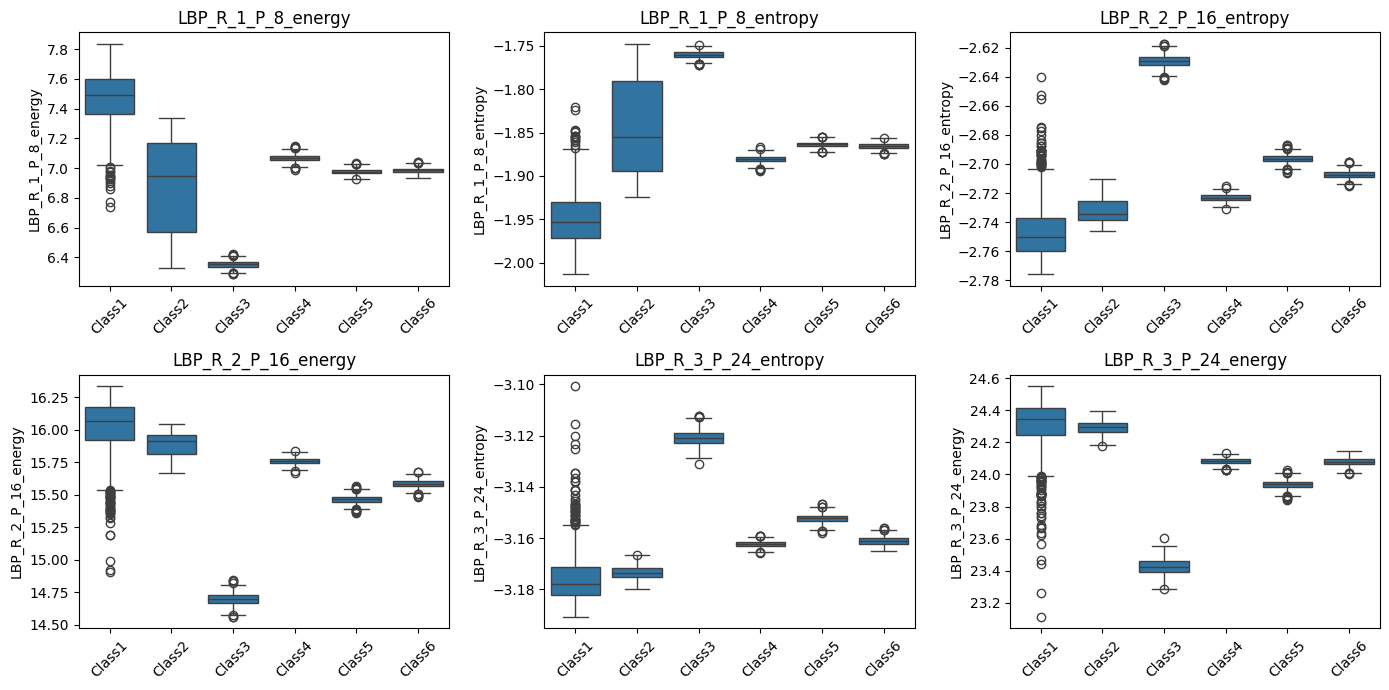

In [13]:
Q1 = features_clean[feature_cols].quantile(0.25)
Q3 = features_clean[feature_cols].quantile(0.75)
IQR = Q3 - Q1

is_outlier = (features_clean[feature_cols] < (Q1 - 1.5 * IQR)) | (features_clean[feature_cols] > (Q3 + 1.5 * IQR))

outlier_summary = (
    pd.DataFrame({
        "n_outlier": is_outlier.sum(),
        "persen": (is_outlier.mean() * 100).round(2),
    })
    .sort_values("persen", ascending=False)
)

print(f"Total sel outlier: {int(is_outlier.values.sum())} dari {is_outlier.size} "
      f"({is_outlier.values.mean() * 100:.2f}%)")
print(f"Baris dengan >=1 outlier: {int(is_outlier.any(axis=1).sum())} dari {len(features_clean)}")
display(outlier_summary.head(10))

top_feats = outlier_summary.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, feat in zip(axes.flat, top_feats):
    sns.boxplot(data=features_clean, x="label", y=feat, ax=ax)
    ax.set_title(feat)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_outlier_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

### Korelasi antarfitur dan sebaran kelas dalam ruang fitur

Pasangan fitur dengan |korelasi| > 0.95: 19 (ditangani lewat remove_multicollinearity di PyCaret)


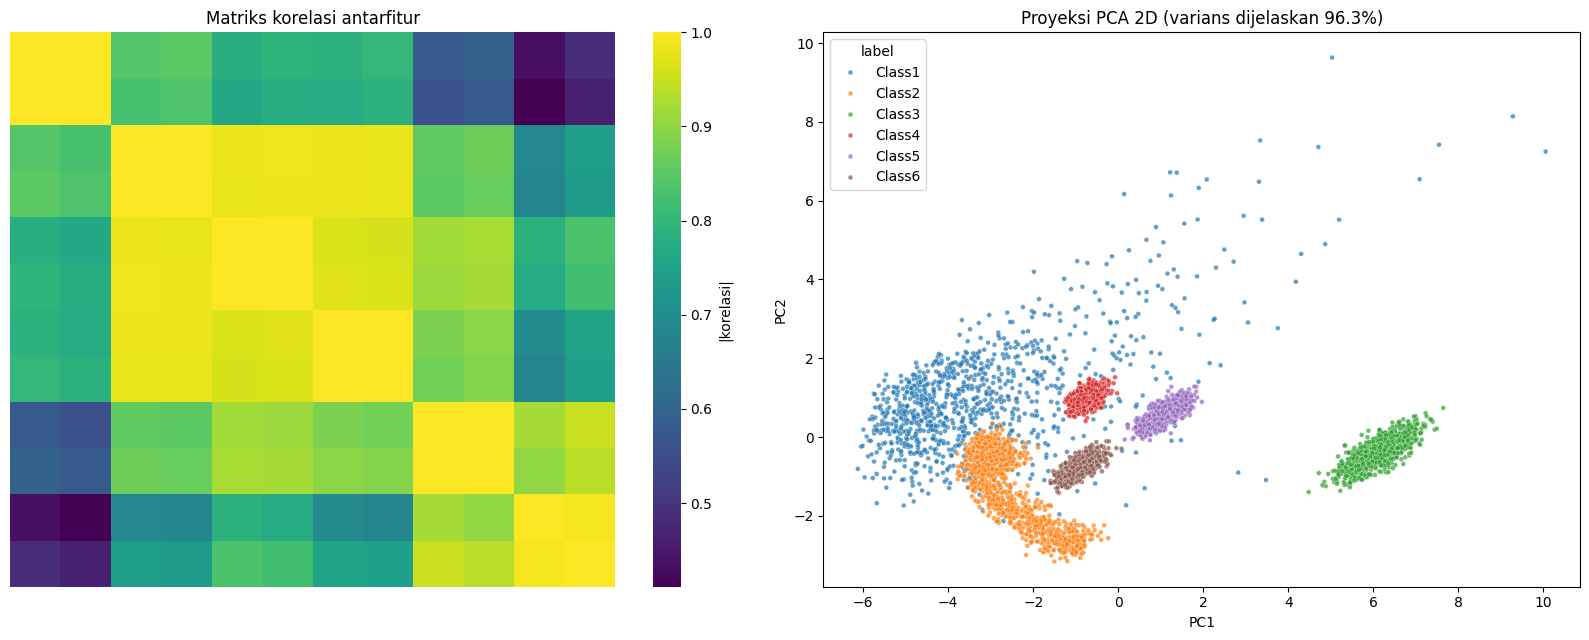

In [14]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

corr = features_clean[feature_cols].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
n_high = int((upper > 0.95).sum().sum())
print(f"Pasangan fitur dengan |korelasi| > 0.95: {n_high} "
      f"(ditangani lewat remove_multicollinearity di PyCaret)")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

sns.heatmap(corr, cmap="viridis", xticklabels=False, yticklabels=False, ax=axes[0], cbar_kws={"label": "|korelasi|"})
axes[0].set_title("Matriks korelasi antarfitur")

X_scaled = StandardScaler().fit_transform(features_clean[feature_cols].fillna(features_clean[feature_cols].median()))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_scaled)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=features_clean["label"], hue_order=sorted(features_clean["label"].unique()),
                s=12, alpha=0.7, ax=axes[1])
axes[1].set_title(f"Proyeksi PCA 2D (varians dijelaskan {pca.explained_variance_ratio_.sum() * 100:.1f}%)")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_correlation_pca.png", dpi=150, bbox_inches="tight")
plt.show()

### Partisi data latih dan data uji

Pembagian **stratified** 80 : 20 agar proporsi kelas terjaga. Data uji **tidak diberikan ke `setup()`** dan hanya dipakai satu kali untuk evaluasi akhir (`predict_model()`).

In [15]:
from sklearn.model_selection import train_test_split

model_df = features_clean.drop(columns=["filename"])
meta_df = features_clean[["filename"]]

train_df, test_df = train_test_split(
    model_df,
    test_size=TEST_SIZE,
    stratify=model_df["label"],
    random_state=RANDOM_STATE,
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(TRAIN_CSV, index=False)
test_df.to_csv(TEST_CSV, index=False)

print("Data latih:", train_df.shape, "| Data uji:", test_df.shape)
display(
    pd.DataFrame({
        "latih": train_df["label"].value_counts().sort_index(),
        "uji": test_df["label"].value_counts().sort_index(),
    })
)

Data latih: (4800, 13) | Data uji: (1200, 13)


,latih,uji
label,,
Class1,800,200
Class2,800,200
Class3,800,200
Class4,800,200
Class5,800,200
Class6,800,200


# TextureGuard AI — Pemodelan dan Evaluasi (PyCaret)

Alur: `setup()` → `compare_models()` → pilih 2 model terbaik → `tune_model()` → visualisasi (Confusion Matrix, ROC/AUC, Feature Importance) → `predict_model()` pada data uji.

## 1. Inisialisasi dengan `setup()`

Pengaturan penting:
- `train_size=0.8` — PyCaret membagi lagi data latih menjadi bagian latih dan *hold-out* internal; validasi silang 5-fold (stratified) dipakai untuk membandingkan model.
- `normalize=True` dengan `robust` — skala berbasis median/IQR, tahan terhadap outlier.
- `numeric_imputation="median"` — penanganan sisa *missing value* di dalam pipeline.
- `remove_multicollinearity=True` (ambang 0.95) — membuang salah satu dari fitur yang berkorelasi sangat tinggi.

In [16]:
from pycaret.classification import (
    setup, compare_models, tune_model, plot_model, predict_model,
    finalize_model, save_model, load_model, pull, get_config,
)

exp = setup(
    data=train_df,
    target="label",
    session_id=RANDOM_STATE,
    train_size=0.8,
    fold=5,
    fold_strategy="stratifiedkfold",
    normalize=True,
    normalize_method="robust",
    numeric_imputation="median",
    remove_multicollinearity=True,
    multicollinearity_threshold=0.95,
    n_jobs=-1,
    verbose=True,
)
setup_table = pull()
setup_table.to_csv(RESULTS_DIR / "04_pycaret_setup.csv", index=False)

,Description,Value
0,Session id,42
1,Target,label
2,Target type,Multiclass
3,Target mapping,"Class1: 0, Class2: 1, Class3: 2, Class4: 3, Class5: 4, Class6: 5"
4,Original data shape,"(4800, 13)"
5,Transformed data shape,"(4800, 9)"
6,Transformed train set shape,"(3840, 9)"
7,Transformed test set shape,"(960, 9)"
8,Numeric features,12
9,Preprocess,True


## 2. Perbandingan model dengan `compare_models()`

Diurutkan berdasarkan **Accuracy**; tiga model teratas disimpan, dua di antaranya dipilih untuk di-*tuning*.

In [17]:
t0 = time.time()
top_models = compare_models(n_select=3, sort="Accuracy", fold=5)
print(f"compare_models selesai dalam {(time.time() - t0) / 60:.1f} menit")

comparison_df = pull()
comparison_df.to_csv(RESULTS_DIR / "05_compare_models.csv")
display(comparison_df)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
qda,Quadratic Discriminant Analysis,0.9977,0.0000,0.9977,0.9977,0.9977,0.9972,0.9972,0.0140
gbc,Gradient Boosting Classifier,0.9891,0.0000,0.9891,0.9892,0.9890,0.9869,0.9869,1.0720
et,Extra Trees Classifier,0.9888,0.9998,0.9888,0.9890,0.9887,0.9866,0.9866,0.0520
rf,Random Forest Classifier,0.9872,0.9994,0.9872,0.9873,0.9872,0.9847,0.9847,0.0680
knn,K Neighbors Classifier,0.9865,0.9956,0.9865,0.9871,0.9863,0.9838,0.9839,0.3800
nb,Naive Bayes,0.9818,0.9990,0.9818,0.9830,0.9817,0.9781,0.9784,0.3780
dt,Decision Tree Classifier,0.9812,0.9887,0.9812,0.9813,0.9812,0.9775,0.9775,0.3740
lda,Linear Discriminant Analysis,0.9773,0.0000,0.9773,0.9777,0.9770,0.9728,0.9730,0.0160
lr,Logistic Regression,0.9682,0.0000,0.9682,0.9680,0.9678,0.9619,0.9620,0.3800
svm,SVM - Linear Kernel,0.9578,0.0000,0.9578,0.9605,0.9570,0.9494,0.9502,0.0220


compare_models selesai dalam 0.4 menit


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
qda,Quadratic Discriminant Analysis,0.9977,0.0000,0.9977,0.9977,0.9977,0.9972,0.9972,0.014
gbc,Gradient Boosting Classifier,0.9891,0.0000,0.9891,0.9892,0.9890,0.9869,0.9869,1.072
et,Extra Trees Classifier,0.9888,0.9998,0.9888,0.9890,0.9887,0.9866,0.9866,0.052
rf,Random Forest Classifier,0.9872,0.9994,0.9872,0.9873,0.9872,0.9847,0.9847,0.068
knn,K Neighbors Classifier,0.9865,0.9956,0.9865,0.9871,0.9863,0.9838,0.9839,0.380
nb,Naive Bayes,0.9818,0.9990,0.9818,0.9830,0.9817,0.9781,0.9784,0.378
dt,Decision Tree Classifier,0.9812,0.9887,0.9812,0.9813,0.9812,0.9775,0.9775,0.374
lda,Linear Discriminant Analysis,0.9773,0.0000,0.9773,0.9777,0.9770,0.9728,0.9730,0.016
lr,Logistic Regression,0.9682,0.0000,0.9682,0.9680,0.9678,0.9619,0.9620,0.380
svm,SVM - Linear Kernel,0.9578,0.0000,0.9578,0.9605,0.9570,0.9494,0.9502,0.022


In [18]:
# Pilih 2 model terbaik hasil perbandingan
selected_models = top_models[:2]
selected_names = comparison_df.iloc[:2]["Model"].tolist()
print("Model terpilih untuk tuning:", selected_names)

Model terpilih untuk tuning: ['Quadratic Discriminant Analysis', 'Gradient Boosting Classifier']


## 3. Hyperparameter tuning dengan `tune_model()`

Pencarian acak (`n_iter=20`) dengan metrik **Accuracy**. `choose_better=True` memastikan hasil tuning hanya dipakai bila benar-benar lebih baik dari model awal.

In [19]:
tuned_models = []
tuning_tables = {}

for model, name in zip(selected_models, selected_names):
    print(f"\n=== Tuning: {name} ===")
    tuned = tune_model(
        model,
        optimize="Accuracy",
        n_iter=20,
        fold=5,
        choose_better=True,
        verbose=False,
    )
    tuning_tables[name] = pull()          # tabel CV per fold + Mean/Std
    tuning_tables[name].to_csv(RESULTS_DIR / f"06_tuning_{name.replace(' ', '_')}.csv")
    display(tuning_tables[name])
    tuned_models.append(tuned)


=== Tuning: Quadratic Discriminant Analysis ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9857,0.0,0.9857,0.9865,0.9856,0.9828,0.9830
1,0.9935,0.0,0.9935,0.9937,0.9935,0.9922,0.9922
2,0.9818,0.0,0.9818,0.9827,0.9816,0.9781,0.9784
3,0.9896,0.0,0.9896,0.9901,0.9895,0.9875,0.9876
4,0.9870,0.0,0.9870,0.9878,0.9869,0.9844,0.9846
Mean,0.9875,0.0,0.9875,0.9881,0.9874,0.9850,0.9852
Std,0.0039,0.0,0.0039,0.0036,0.0040,0.0047,0.0046



=== Tuning: Gradient Boosting Classifier ===


,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9883,0.0,0.9883,0.9885,0.9883,0.9859,0.9860
1,0.9896,0.0,0.9896,0.9896,0.9895,0.9875,0.9875
2,0.9935,0.0,0.9935,0.9936,0.9935,0.9922,0.9922
3,0.9909,0.0,0.9909,0.9910,0.9909,0.9891,0.9891
4,0.9896,0.0,0.9896,0.9898,0.9895,0.9875,0.9876
Mean,0.9904,0.0,0.9904,0.9905,0.9903,0.9884,0.9885
Std,0.0018,0.0,0.0018,0.0017,0.0018,0.0021,0.0021


## 4. Visualisasi performa model

Untuk setiap model terpilih: *Confusion Matrix*, kurva *ROC/AUC*, dan *Feature Importance*.
Plot dibuat pada **hold-out internal PyCaret** (bukan data uji akhir). `feature` hanya tersedia untuk model berbasis pohon/linier; untuk model lain dipakai *permutation importance* sebagai cadangan.


######## Quadratic Discriminant Analysis ########


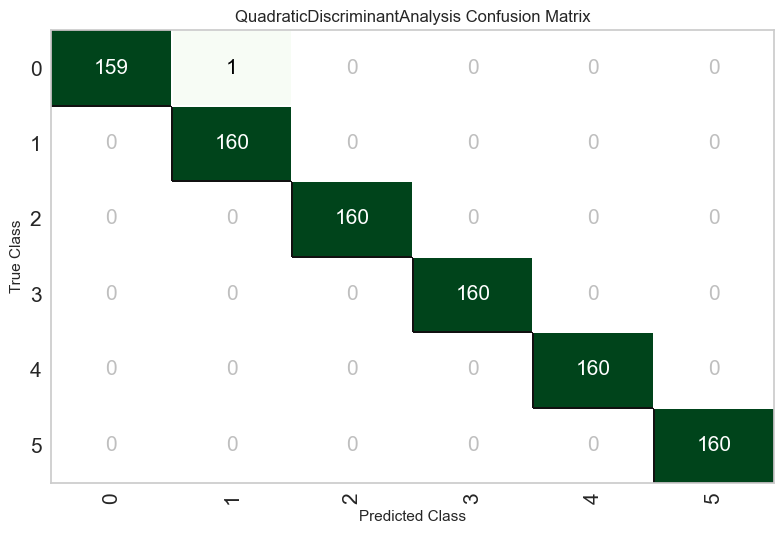

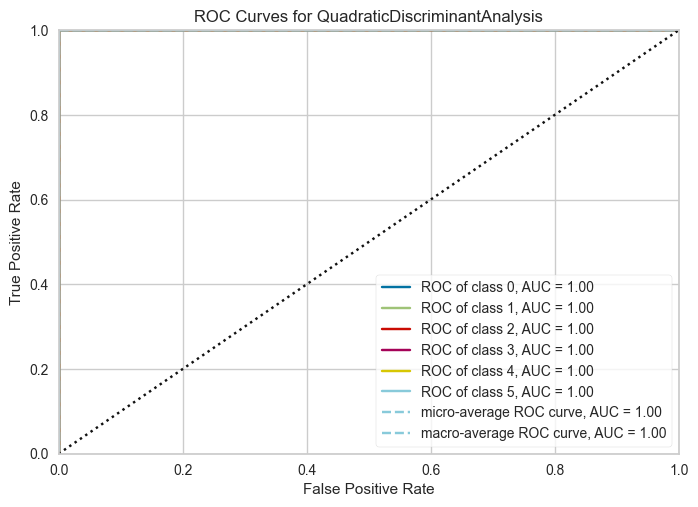

[info] plot 'feature' tidak tersedia untuk Quadratic Discriminant Analysis (TypeError); memakai permutation importance.


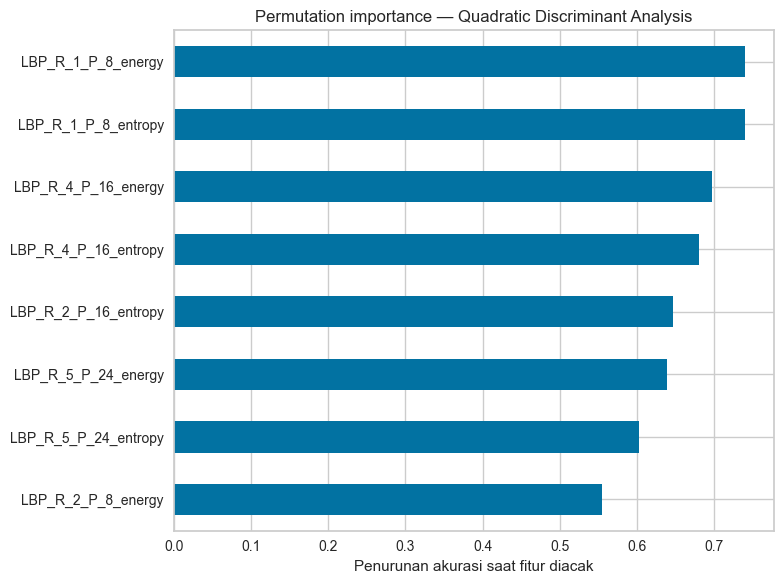


######## Gradient Boosting Classifier ########


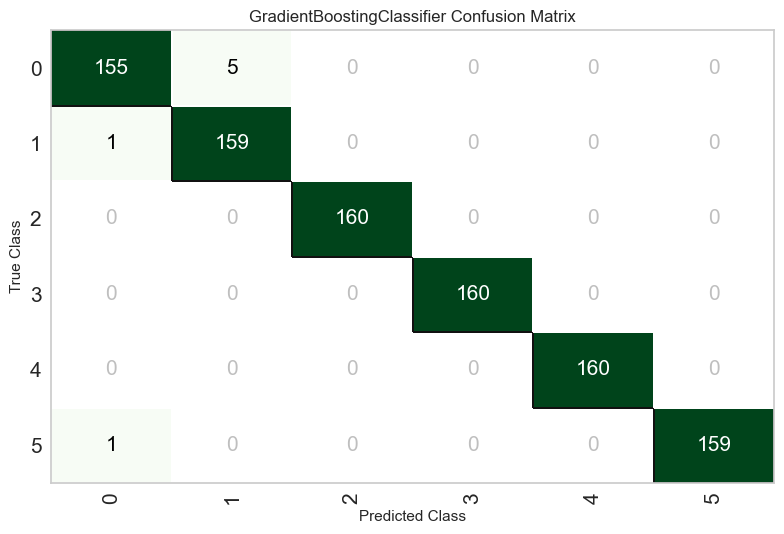

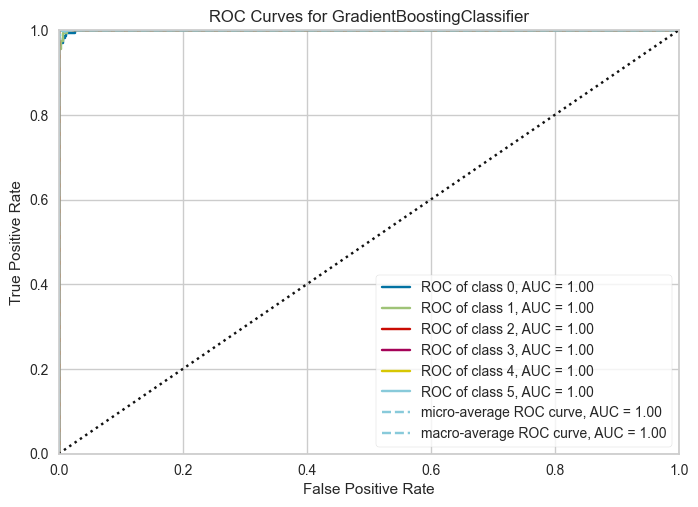

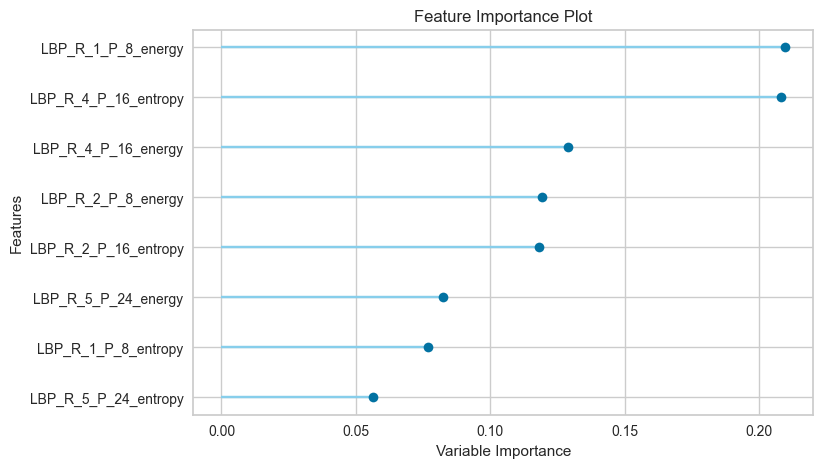

In [20]:
import shutil
from sklearn.inspection import permutation_importance


def permutation_importance_plot(model, name, top_n=15):
    # model hasil compare/tune adalah estimator murni -> gunakan data hold-out yang sudah ditransformasi
    X_hold = get_config("X_test_transformed")
    y_hold = get_config("y_test_transformed")
    res = permutation_importance(model, X_hold, y_hold, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.Series(res.importances_mean, index=X_hold.columns).sort_values().tail(top_n)
    imp.plot(kind="barh", figsize=(8, 6), title=f"Permutation importance — {name}")
    plt.xlabel("Penurunan akurasi saat fitur diacak")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"09_feature_importance_{name.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()


for model, name in zip(tuned_models, selected_names):
    tag = name.replace(" ", "_")
    print(f"\n######## {name} ########")

    for plot, fname in [("confusion_matrix", "07_confusion_matrix"), ("auc", "08_roc_auc")]:
        plot_model(model, plot=plot)                                   # tampilkan di notebook
        saved = plot_model(model, plot=plot, save=True)                # simpan ke berkas
        shutil.move(saved, RESULTS_DIR / f"{fname}_{tag}.png")

    try:
        plot_model(model, plot="feature")
        saved = plot_model(model, plot="feature", save=True)
        shutil.move(saved, RESULTS_DIR / f"09_feature_importance_{tag}.png")
    except Exception as e:
        print(f"[info] plot 'feature' tidak tersedia untuk {name} ({type(e).__name__}); memakai permutation importance.")
        permutation_importance_plot(model, name)

## 5. Evaluasi akhir pada data uji dengan `predict_model()`

Data uji (`test_df`) belum pernah dilihat oleh `setup()`, `compare_models()`, maupun `tune_model()`.

In [21]:
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, ConfusionMatrixDisplay, roc_curve, auc, roc_auc_score,
)
from sklearn.preprocessing import label_binarize

test_results = []
test_predictions = {}

for model, name in zip(tuned_models, selected_names):
    pred = predict_model(model, data=test_df, raw_score=True, round=8, verbose=False)
    test_predictions[name] = pred

    y_true = pred["label"]
    y_pred = pred["prediction_label"]
    class_names = sorted(y_true.unique())
    proba_cols = [f"prediction_score_{c}" for c in class_names]

    # Normalisasi ulang tiap baris agar jumlah probabilitas tepat 1 (sisa galat pembulatan),
    # sebagaimana disyaratkan roc_auc_score untuk kasus multikelas.
    proba = pred[proba_cols].values
    proba = proba / proba.sum(axis=1, keepdims=True)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro"),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro"),
        "AUC (OvR macro)": roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=class_names),
    })

    print(f"\n===== {name} — Laporan klasifikasi pada data uji =====")
    print(classification_report(y_true, y_pred, digits=4))

test_summary = pd.DataFrame(test_results).set_index("Model").round(4)
test_summary.to_csv(RESULTS_DIR / "10_test_summary.csv")
display(test_summary)


===== Quadratic Discriminant Analysis — Laporan klasifikasi pada data uji =====
              precision    recall  f1-score   support

      Class1     1.0000    1.0000    1.0000       200
      Class2     1.0000    1.0000    1.0000       200
      Class3     1.0000    1.0000    1.0000       200
      Class4     1.0000    1.0000    1.0000       200
      Class5     1.0000    1.0000    1.0000       200
      Class6     1.0000    1.0000    1.0000       200

    accuracy                         1.0000      1200
   macro avg     1.0000    1.0000    1.0000      1200
weighted avg     1.0000    1.0000    1.0000      1200


===== Gradient Boosting Classifier — Laporan klasifikasi pada data uji =====
              precision    recall  f1-score   support

      Class1     0.9897    0.9650    0.9772       200
      Class2     0.9801    0.9850    0.9825       200
      Class3     0.9950    1.0000    0.9975       200
      Class4     0.9950    1.0000    0.9975       200
      Class5     1.0000    

,Accuracy,Precision (macro),Recall (macro),F1 (macro),AUC (OvR macro)
Model,,,,,
Quadratic Discriminant Analysis,1.0000,1.0000,1.0000,1.0000,1.0000
Gradient Boosting Classifier,0.9917,0.9917,0.9917,0.9916,0.9998


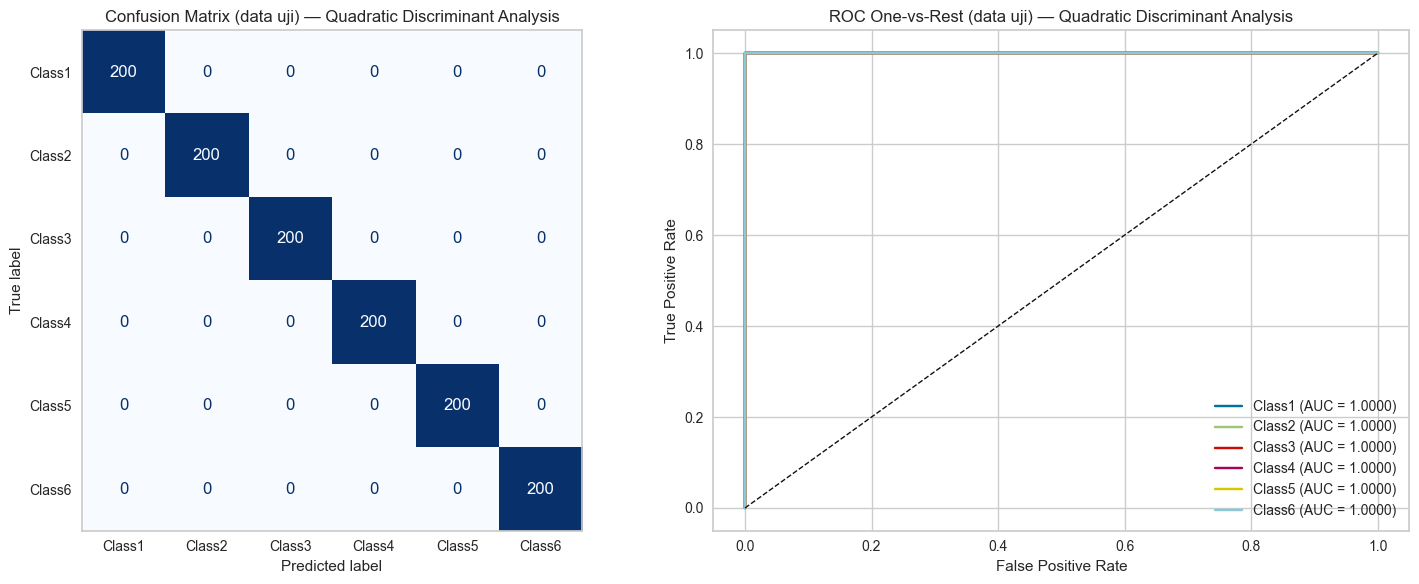

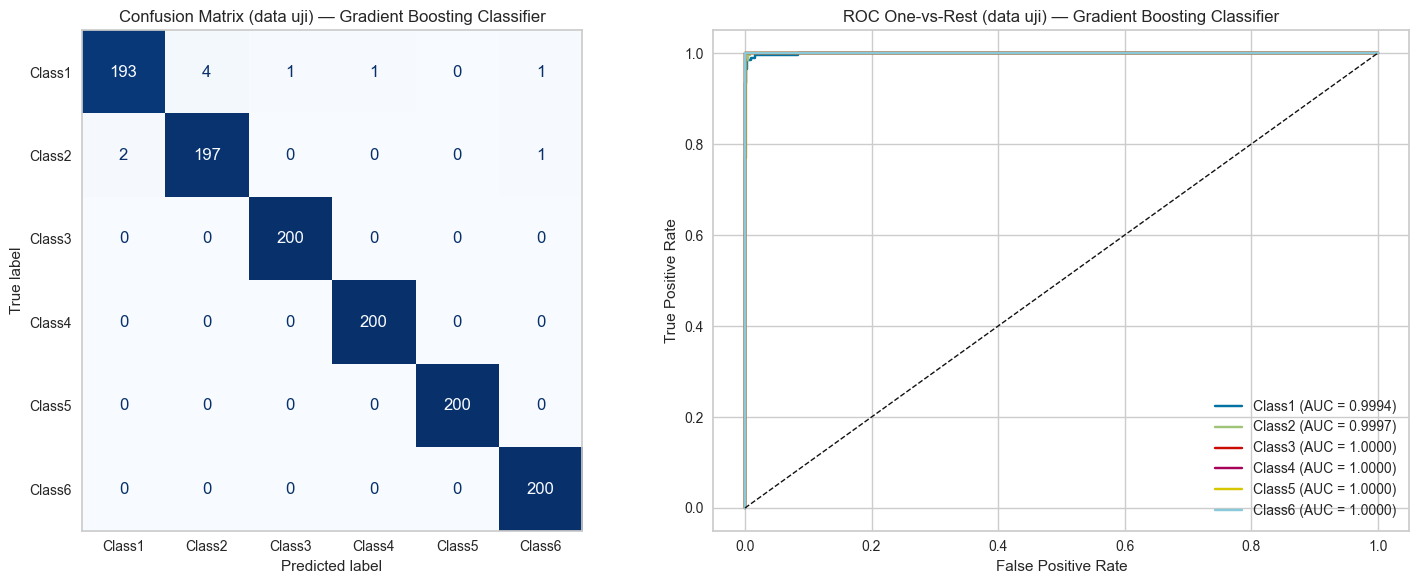

In [22]:
# Confusion matrix dan ROC multikelas pada data uji
for name, pred in test_predictions.items():
    tag = name.replace(" ", "_")
    y_true = pred["label"]
    y_pred = pred["prediction_label"]
    class_names = sorted(y_true.unique())

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=class_names, cmap="Blues", ax=axes[0], colorbar=False
    )
    axes[0].grid(False)
    axes[0].set_title(f"Confusion Matrix (data uji) — {name}")

    y_bin = label_binarize(y_true, classes=class_names)
    for i, c in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, i], pred[f"prediction_score_{c}"])
        axes[1].plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.4f})")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
    axes[1].set_title(f"ROC One-vs-Rest (data uji) — {name}")
    axes[1].legend(loc="lower right")

    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"11_test_cm_roc_{tag}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 6. Finalisasi dan penyimpanan model

Model dengan akurasi validasi silang terbaik dilatih ulang pada **seluruh data latih** (`finalize_model()`), diuji sekali lagi pada data uji, lalu disimpan.

In [23]:
# Pilih model terbaik berdasarkan rata-rata Accuracy validasi silang (bukan data uji)
cv_acc = [tuning_tables[n].loc["Mean", "Accuracy"] for n in selected_names]
best_idx = int(np.argmax(cv_acc))
best_name, best_model = selected_names[best_idx], tuned_models[best_idx]
print(f"Model terbaik berdasarkan CV: {best_name} (Accuracy CV = {cv_acc[best_idx]:.4f})")

final_model = finalize_model(best_model)
final_pred = predict_model(final_model, data=test_df, verbose=False)

final_acc = accuracy_score(final_pred["label"], final_pred["prediction_label"])
final_f1 = f1_score(final_pred["label"], final_pred["prediction_label"], average="macro")
print(f"Data uji — Accuracy: {final_acc:.4f} | F1 macro: {final_f1:.4f}")

save_model(final_model, str(RESULTS_DIR / "best_texture_model"))
print("Model tersimpan:", (RESULTS_DIR / "best_texture_model.pkl").resolve())

Model terbaik berdasarkan CV: Gradient Boosting Classifier (Accuracy CV = 0.9904)
Data uji — Accuracy: 0.9925 | F1 macro: 0.9925
Transformation Pipeline and Model Successfully Saved
Model tersimpan: C:\Users\acer\Desktop\evanalifian\textureguard-ai-dagm2007\results\best_texture_model.pkl


# Ringkasan dan Kesimpulan

In [24]:
print("=" * 60)
print("RINGKASAN PROYEK TEXTUREGUARD AI")
print("=" * 60)
print(f"Dataset            : DAGM 2007 (Class1-Class6), {len(image_info)} citra, 6 kelas")
print(f"Pra-pemrosesan     : grayscale, resize {IMG_SIZE}x{IMG_SIZE}, uint8")
print(f"Fitur PyFeats      : {len(feature_cols)} fitur Local Binary Pattern ({len(LBP_SCALES)} skala x energy/entropy)")
print(f"Partisi            : latih {len(train_df)} | uji {len(test_df)} (stratified)")
print(f"Model dibandingkan : {len(comparison_df)} model (compare_models)")
print(f"Model di-tuning    : {', '.join(selected_names)}")
print(f"Model terbaik (CV) : {best_name}")
print(f"Hasil data uji     : Accuracy {final_acc:.4f} | F1 macro {final_f1:.4f}")
print("=" * 60)
display(test_summary)

RINGKASAN PROYEK TEXTUREGUARD AI
Dataset            : DAGM 2007 (Class1-Class6), 6000 citra, 6 kelas
Pra-pemrosesan     : grayscale, resize 128x128, uint8
Fitur PyFeats      : 12 fitur Local Binary Pattern (6 skala x energy/entropy)
Partisi            : latih 4800 | uji 1200 (stratified)
Model dibandingkan : 13 model (compare_models)
Model di-tuning    : Quadratic Discriminant Analysis, Gradient Boosting Classifier
Model terbaik (CV) : Gradient Boosting Classifier
Hasil data uji     : Accuracy 0.9925 | F1 macro 0.9925


,Accuracy,Precision (macro),Recall (macro),F1 (macro),AUC (OvR macro)
Model,,,,,
Quadratic Discriminant Analysis,1.0000,1.0000,1.0000,1.0000,1.0000
Gradient Boosting Classifier,0.9917,0.9917,0.9917,0.9916,0.9998


### Kesimpulan

> **Catatan**: lengkapi paragraf berikut dengan angka dari hasil eksekusi notebook milikmu.

1. **Pipeline**: citra DAGM 2007 dipra-proses (grayscale, resize), lalu diekstraksi dengan metode **Local Binary Pattern (LBP)** memakai PyFeats (6 skala `(P, R)` × energy/entropy = 12 fitur), lalu dimodelkan dengan PyCaret.
2. **Perbandingan model**: `compare_models()` menempatkan *(isi nama model)* dan *(isi nama model)* sebagai dua model terbaik dengan akurasi CV *(isi angka)*.
3. **Tuning**: *(jelaskan apakah tuning meningkatkan skor atau model awal dipertahankan karena `choose_better=True`)*.
4. **Evaluasi akhir**: pada data uji model terbaik mencapai akurasi *(isi angka)* dan F1 macro *(isi angka)*. Confusion matrix menunjukkan *(kelas mana yang paling sering tertukar, bila ada)*.
5. **Fitur penting**: *(sebutkan 3–5 fitur teratas dari grafik feature importance, misalnya skala `(P, R)` mana dan apakah `energy` atau `entropy` yang paling berpengaruh)*.
6. **Keterbatasan**: setiap kelas DAGM 2007 memiliki latar tekstur yang sangat berbeda, sehingga klasifikasi antar-kelas relatif mudah dan skor dapat mendekati sempurna. Penelitian lanjutan dapat mengklasifikasikan **ada/tidaknya cacat** di dalam satu kelas tekstur (tugas yang jauh lebih sulit), atau menguji ketahanan terhadap derau dan variasi pencahayaan. LBP juga hanya menangkap pola **lokal**; ringkasan energy/entropy membuang informasi lokasi dan detail distribusi kode, sehingga pada kasus yang lebih sulit dapat dipertimbangkan histogram LBP lengkap atau gabungan dengan metode lain.

**Sumber dataset**: DAGM 2007 — https://conferences.mpi-inf.mpg.de/dagm/2007/prizes.html